# Prediksi Waktu Tunggu Antrean Klinik dengan Random Forest Regressor

Notebook ini menyusun alur dari **dataset awal → pemeriksaan data → cleansing → eksplorasi → feature engineering → training → evaluasi → estimasi antrean**.

**Tujuan:** memperkirakan waktu tunggu pasien (menit) berdasarkan data historis pelayanan. Notebook ini juga menyiapkan contoh simulasi estimasi antrean yang dapat dipakai saat sistem menerima data antrean terbaru.

> **Penting:** file yang tersedia berisi data sintetis/dummy. Hasil model dari data sintetis hanya menguji alur teknis, bukan membuktikan akurasi pada kondisi klinik nyata. Monitoring *real-time* memerlukan data antrean terkini dari database/API aplikasi; Excel historis saja tidak bisa memperbarui kondisi secara real-time.


# **1. Import Library**
Library digunakan untuk membaca dan membersihkan Excel, membuat visualisasi, melatih model regresi, serta mengevaluasi prediksi.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)


## **2. Membaca dataset awal**
Unggah file Excel ke Google Colab, atau simpan di Google Drive lalu sesuaikan `FILE_PATH`. Notebook membaca sheet **Data Riwayat Antrian** sebagai data utama. Sheet ringkasan bukan target training karena ringkasan per hari bukan satu baris per pasien.

In [ ]:
# Opsi A: upload file dari komputer ke Colab
from google.colab import files
uploaded = files.upload()

# Pilih nama file Excel yang diunggah
FILE_PATH = next(iter(uploaded.keys()))

# Jika memakai Google Drive, komentari 3 baris di atas dan gunakan:
# from google.colab import drive
# drive.mount('/content/drive')
# FILE_PATH = '/content/drive/MyDrive/Colab Notebooks/Skripsi/Dataset.xlsx'

df_raw = pd.read_excel(FILE_PATH, sheet_name="Data Riwayat Antrian")
print("Ukuran dataset awal:", df_raw.shape)
display(df_raw.head())


Saving Dataset.xlsx to Dataset.xlsx
Ukuran dataset awal: (4248, 15)


,ID Pasien,Tanggal Kunjungan,Nomor Antrean,Cara Daftar,Waktu Pendaftaran,Waktu Dipanggil,Waktu Mulai Pemeriksaan,Waktu Selesai Pemeriksaan,Status Pasien,Prioritas,Jadwal Praktik Dokter,Ruang,Waktu Tunggu (menit),Durasi Pemeriksaan (menit),Status Kehadiran
0,P0391,2026-01-01,A001,Langsung,06:46:00,06:58:00,07:00:00,07:11:00,Selesai,Tidak,Pagi 07.00 - 10.00 WIB,Ruang Praktik 1,14,11,Hadir
1,P0392,2026-01-01,A002,Langsung,06:52:00,07:20:00,07:21:00,07:32:00,Selesai,Tidak,Pagi 07.00 - 10.00 WIB,Ruang Praktik 1,29,11,Hadir
2,P0393,2026-01-01,A003,Langsung,07:11:00,07:40:00,07:41:00,07:58:00,Selesai,Tidak,Pagi 07.00 - 10.00 WIB,Ruang Praktik 1,30,17,Hadir
3,P0394,2026-01-01,A004,Langsung,07:23:00,08:00:00,08:02:00,08:12:00,Selesai,Tidak,Pagi 07.00 - 10.00 WIB,Ruang Praktik 1,39,10,Hadir
4,P0395,2026-01-01,A005,Langsung,08:03:00,08:21:00,08:22:00,08:32:00,Selesai,Tidak,Pagi 07.00 - 10.00 WIB,Ruang Praktik 1,19,10,Hadir


## **3. Memahami struktur dataset awal**
Periksa nama kolom, tipe data, jumlah nilai terisi, duplikasi, dan ringkasan statistik sebelum mengubah data.

In [ ]:
print("Informasi struktur:")
df_raw.info()

print("\nJumlah nilai kosong per kolom:")
display(df_raw.isna().sum().to_frame("Jumlah Kosong"))

print("\nJumlah baris duplikat penuh:", df_raw.duplicated().sum())
print("\nStatistik numerik:")
display(df_raw.describe(include="all").T)


Informasi struktur:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4248 entries, 0 to 4247
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   ID Pasien                   4248 non-null   object        
 1   Tanggal Kunjungan           4248 non-null   datetime64[ns]
 2   Nomor Antrean               4248 non-null   object        
 3   Cara Daftar                 4248 non-null   object        
 4   Waktu Pendaftaran           4248 non-null   object        
 5   Waktu Dipanggil             4248 non-null   object        
 6   Waktu Mulai Pemeriksaan     4248 non-null   object        
 7   Waktu Selesai Pemeriksaan   4248 non-null   object        
 8   Status Pasien               4248 non-null   object        
 9   Prioritas                   4248 non-null   object        
 10  Jadwal Praktik Dokter       4248 non-null   object        
 11  Ruang                       4248 non

,Jumlah Kosong
ID Pasien,0
Tanggal Kunjungan,0
Nomor Antrean,0
Cara Daftar,0
Waktu Pendaftaran,0
Waktu Dipanggil,0
Waktu Mulai Pemeriksaan,0
Waktu Selesai Pemeriksaan,0
Status Pasien,0
Prioritas,0



Jumlah baris duplikat penuh: 0

Statistik numerik:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ID Pasien,4248,4248,P0390,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tanggal Kunjungan,4248,NaN,NaN,NaN,2026-05-26 07:43:43.728813568,2026-01-01 00:00:00,2026-03-14 00:00:00,2026-05-26 12:00:00,2026-08-07 00:00:00,2026-10-19 00:00:00,NaN
Nomor Antrean,4248,18,A001,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cara Daftar,4248,1,Langsung,4248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Waktu Pendaftaran,4248,405,07:04:00,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Waktu Dipanggil,4248,100,09:44:00,74,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Waktu Mulai Pemeriksaan,4248,25,07:00:00,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Waktu Selesai Pemeriksaan,4248,255,17:24:00,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status Pasien,4248,1,Selesai,4248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Prioritas,4248,2,Tidak,4118,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## **4. Data cleansing**
Langkah ini:
1. Menyeragamkan spasi pada nama kolom dan teks.
2. Mengubah tanggal dan jam ke tipe data yang tepat.
3. Mengubah kolom numerik menjadi angka.
4. Menghapus duplikasi penuh.
5. Memeriksa nilai target yang kosong/tidak masuk akal.
6. Memvalidasi urutan waktu.

Baris dengan target waktu tunggu yang hilang atau negatif tidak bisa dipakai untuk melatih model. Jangan langsung mengisi target dengan median karena itu menciptakan label buatan.

In [ ]:
df = df_raw.copy()

# Rapikan nama kolom dan nilai teks
df.columns = df.columns.astype(str).str.strip()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].map(lambda x: x.strip() if isinstance(x, str) else x)

# Konversi tipe tanggal, jam, dan angka
df["Tanggal Kunjungan"] = pd.to_datetime(df["Tanggal Kunjungan"], errors="coerce")
time_cols = [
    "Waktu Pendaftaran", "Waktu Dipanggil",
    "Waktu Mulai Pemeriksaan", "Waktu Selesai Pemeriksaan"
]
for col in time_cols:
    # Normalisasi nilai waktu Excel/string menjadi HH:MM:SS
    df[col] = pd.to_datetime(df[col].astype(str), format="%H:%M:%S", errors="coerce").dt.time

numeric_cols = ["Waktu Tunggu (menit)", "Durasi Pemeriksaan (menit)"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

before = len(df)
df = df.drop_duplicates().copy()
print("Duplikasi penuh yang dihapus:", before - len(df))

# Cek nilai target
print("Target kosong:", df["Waktu Tunggu (menit)"].isna().sum())
print("Target <= 0:", (df["Waktu Tunggu (menit)"] <= 0).sum())
print("Target > 240 menit:", (df["Waktu Tunggu (menit)"] > 240).sum())

# Target wajib valid untuk supervised learning
df = df[
    df["Tanggal Kunjungan"].notna()
    & df["Waktu Tunggu (menit)"].notna()
    & (df["Waktu Tunggu (menit)"] >= 0)
].copy()

print("Ukuran setelah cleansing dasar:", df.shape)
display(df.head())


Duplikasi penuh yang dihapus: 0
Target kosong: 0
Target <= 0: 0
Target > 240 menit: 0
Ukuran setelah cleansing dasar: (4248, 15)


,ID Pasien,Tanggal Kunjungan,Nomor Antrean,Cara Daftar,Waktu Pendaftaran,Waktu Dipanggil,Waktu Mulai Pemeriksaan,Waktu Selesai Pemeriksaan,Status Pasien,Prioritas,Jadwal Praktik Dokter,Ruang,Waktu Tunggu (menit),Durasi Pemeriksaan (menit),Status Kehadiran
0,P0391,2026-01-01,A001,Langsung,06:46:00,06:58:00,07:00:00,07:11:00,Selesai,Tidak,Pagi 07.00 - 10.00 WIB,Ruang Praktik 1,14,11,Hadir
1,P0392,2026-01-01,A002,Langsung,06:52:00,07:20:00,07:21:00,07:32:00,Selesai,Tidak,Pagi 07.00 - 10.00 WIB,Ruang Praktik 1,29,11,Hadir
2,P0393,2026-01-01,A003,Langsung,07:11:00,07:40:00,07:41:00,07:58:00,Selesai,Tidak,Pagi 07.00 - 10.00 WIB,Ruang Praktik 1,30,17,Hadir
3,P0394,2026-01-01,A004,Langsung,07:23:00,08:00:00,08:02:00,08:12:00,Selesai,Tidak,Pagi 07.00 - 10.00 WIB,Ruang Praktik 1,39,10,Hadir
4,P0395,2026-01-01,A005,Langsung,08:03:00,08:21:00,08:22:00,08:32:00,Selesai,Tidak,Pagi 07.00 - 10.00 WIB,Ruang Praktik 1,19,10,Hadir


### **4.1 Validasi konsistensi waktu**
Waktu tunggu idealnya dihitung dari definisi yang disepakati klinik. Pada dataset ini, kolom target `Waktu Tunggu (menit)` tidak selalu harus sama dengan selisih pendaftaran ke mulai pemeriksaan jika definisinya berbeda. Kita bandingkan keduanya untuk menemukan ketidakkonsistenan, bukan otomatis mengganti target tanpa verifikasi.

In [ ]:
def time_to_seconds(value):
    if pd.isna(value):
        return np.nan
    return value.hour * 3600 + value.minute * 60 + value.second

df["Detik Daftar"] = df["Waktu Pendaftaran"].apply(time_to_seconds)
df["Detik Mulai"] = df["Waktu Mulai Pemeriksaan"].apply(time_to_seconds)

# Selisih waktu daftar -> mulai, termasuk kemungkinan lintas tengah malam
diff = (df["Detik Mulai"] - df["Detik Daftar"]) / 60
diff = diff.where(diff >= 0, diff + 24 * 60)
df["Selisih Daftar-ke-Mulai (menit)"] = diff

df["Selisih Target (menit)"] = (
    df["Waktu Tunggu (menit)"] - df["Selisih Daftar-ke-Mulai (menit)"]
).abs()

print("Median selisih antara target dan selisih waktu aktual:",
      round(df["Selisih Target (menit)"].median(), 2), "menit")
display(df[[
    "Tanggal Kunjungan", "Waktu Pendaftaran", "Waktu Mulai Pemeriksaan",
    "Waktu Tunggu (menit)", "Selisih Daftar-ke-Mulai (menit)",
    "Selisih Target (menit)"
]].head(10))


Median selisih antara target dan selisih waktu aktual: 0.0 menit


,Tanggal Kunjungan,Waktu Pendaftaran,Waktu Mulai Pemeriksaan,Waktu Tunggu (menit),Selisih Daftar-ke-Mulai (menit),Selisih Target (menit)
0,2026-01-01,06:46:00,07:00:00,14,14.0,0.0
1,2026-01-01,06:52:00,07:21:00,29,29.0,0.0
2,2026-01-01,07:11:00,07:41:00,30,30.0,0.0
3,2026-01-01,07:23:00,08:02:00,39,39.0,0.0
4,2026-01-01,08:03:00,08:22:00,19,19.0,0.0
5,2026-01-01,08:15:00,08:43:00,28,28.0,0.0
6,2026-01-01,08:35:00,09:04:00,29,29.0,0.0
7,2026-01-01,09:13:00,09:24:00,11,11.0,0.0
8,2026-01-01,09:07:00,09:45:00,38,38.0,0.0
9,2026-01-01,15:45:00,16:00:00,15,15.0,0.0


## **5. Pemeriksaan jadwal praktik**
Jadwal rutin dari papan klinik adalah Senin–Sabtu, sesi pagi 07.00–10.00 WIB dan sore 16.00–20.00 WIB. Minggu/tanggal merah hanya dengan perjanjian. Kode berikut memberi label hari dan sesi berdasarkan waktu mulai pemeriksaan.

**Catatan:** tanggal merah harus diverifikasi dari kalender resmi dan data perjanjian klinik. Notebook tidak menganggap semua tanggal merah otomatis tutup.

In [ ]:
df["Hari"] = df["Tanggal Kunjungan"].dt.day_name()
df["Nomor Hari"] = df["Tanggal Kunjungan"].dt.dayofweek  # Senin=0, Minggu=6
df["Jam Mulai"] = df["Waktu Mulai Pemeriksaan"].apply(
    lambda t: t.hour + t.minute / 60 if pd.notna(t) else np.nan
)

def tentukan_sesi(row):
    if row["Nomor Hari"] == 6:
        return "Minggu - Perjanjian"
    if 7 <= row["Jam Mulai"] < 10:
        return "Pagi"
    if 16 <= row["Jam Mulai"] < 20:
        return "Sore"
    return "Di luar jadwal rutin"

df["Sesi"] = df.apply(tentukan_sesi, axis=1)
display(df["Sesi"].value_counts().to_frame("Jumlah Baris"))
display(df.groupby(["Hari", "Sesi"], dropna=False).size().to_frame("Jumlah Pasien"))


,Jumlah Baris
Sesi,
Pagi,2124
Sore,2124


Jumlah Pasien
Hari      Sesi               
Friday    Pagi            378
          Sore            378
Monday    Pagi            378
          Sore            378
Saturday  Pagi            252
          Sore            252
Thursday  Pagi            378
          Sore            378
Tuesday   Pagi            369
          Sore            369
Wednesday Pagi            369
          Sore            369

## **6. Eksplorasi data (EDA)**
Lihat distribusi waktu tunggu, rata-rata per sesi, jumlah pasien per tanggal, dan pola dari waktu ke waktu. Ini membantu memahami data sebelum membangun model.

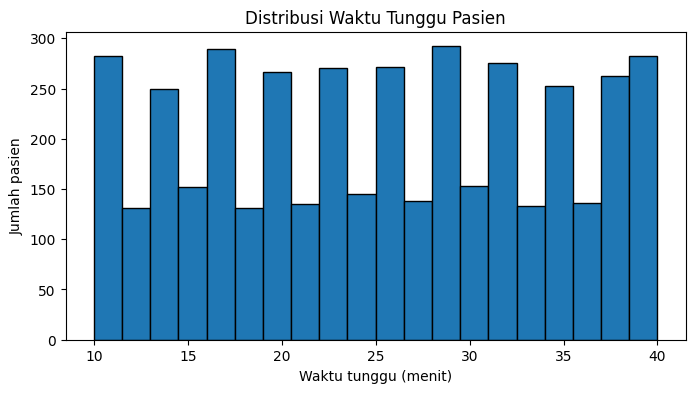

,Rata-rata waktu tunggu (menit)
Sesi,
Sore,24.846516
Pagi,25.129944


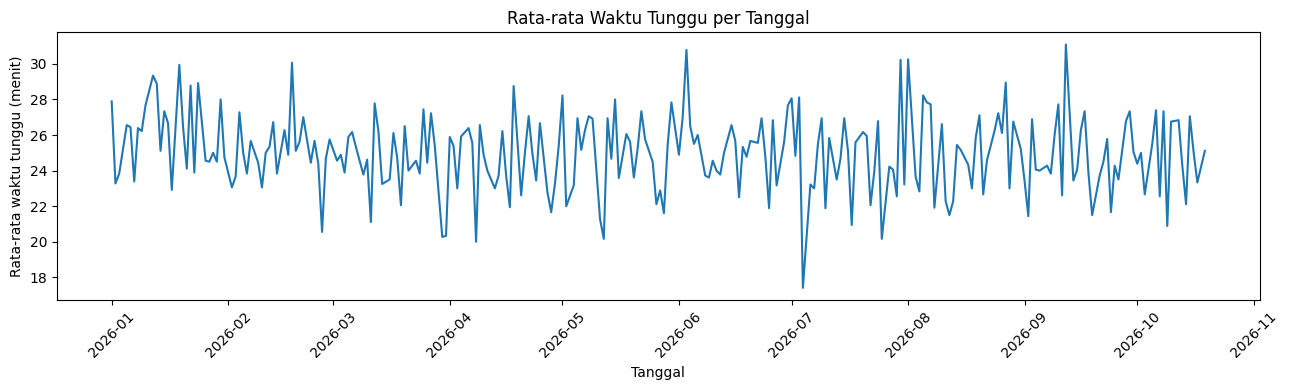

In [ ]:
plt.figure(figsize=(8, 4))
df["Waktu Tunggu (menit)"].plot(kind="hist", bins=20, edgecolor="black")
plt.title("Distribusi Waktu Tunggu Pasien")
plt.xlabel("Waktu tunggu (menit)")
plt.ylabel("Jumlah pasien")
plt.show()

avg_session = df.groupby("Sesi")["Waktu Tunggu (menit)"].mean().sort_values()
display(avg_session.to_frame("Rata-rata waktu tunggu (menit)"))

daily = df.groupby(df["Tanggal Kunjungan"].dt.date).agg(
    Jumlah_Pasien=("ID Pasien", "count"),
    Rata_rata_Tunggu=("Waktu Tunggu (menit)", "mean")
)
fig, ax1 = plt.subplots(figsize=(13, 4))
ax1.plot(pd.to_datetime(daily.index), daily["Rata_rata_Tunggu"])
ax1.set_title("Rata-rata Waktu Tunggu per Tanggal")
ax1.set_xlabel("Tanggal")
ax1.set_ylabel("Rata-rata waktu tunggu (menit)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## **7. Feature engineering dan pemilihan fitur**
Model akan memperkirakan waktu tunggu **pada saat pasien mendaftar**. Karena itu, kita hanya boleh memakai informasi yang sudah tersedia pada saat pendaftaran.

**Tidak digunakan sebagai fitur:** waktu dipanggil, waktu mulai pemeriksaan, waktu selesai pemeriksaan, durasi pemeriksaan, dan status akhir. Informasi tersebut baru diketahui setelah pelayanan berjalan dan dapat menyebabkan *data leakage*.

Fitur yang dipakai: hari, bulan, akhir pekan, jam pendaftaran, sesi praktik, nomor antrean, cara daftar, prioritas, serta jumlah antrean yang mendahului pasien (jika nomor antrean mencerminkan urutan antrean).

In [ ]:
# Buat fitur dari tanggal dan waktu pendaftaran
df["Bulan"] = df["Tanggal Kunjungan"].dt.month
df["Hari_Dalam_Minggu"] = df["Tanggal Kunjungan"].dt.dayofweek
df["Akhir_Pekan"] = (df["Hari_Dalam_Minggu"] == 5).astype(int)

def time_to_hour(value):
    if pd.isna(value):
        return np.nan
    return value.hour + value.minute / 60 + value.second / 3600

df["Jam_Pendaftaran"] = df["Waktu Pendaftaran"].apply(time_to_hour)

# Ambil angka dari nomor antrean, mis. A012 -> 12
df["Nomor_Antrean_Angka"] = pd.to_numeric(
    df["Nomor Antrean"].astype(str).str.extract(r"(\d+)")[0], errors="coerce"
)
df["Antrean_Sebelumnya"] = (df["Nomor_Antrean_Angka"] - 1).clip(lower=0)

# Sesi diperkirakan dari jam pendaftaran, yang tersedia saat prediksi
def sesi_dari_jam(jam):
    if pd.isna(jam):
        return "Tidak diketahui"
    if 5 <= jam < 10:
        return "Pagi"
    if 14 <= jam < 20:
        return "Sore"
    return "Di luar jadwal"

df["Sesi_Pendaftaran"] = df["Jam_Pendaftaran"].apply(sesi_dari_jam)

target = "Waktu Tunggu (menit)"
fitur_numerik = [
    "Bulan", "Hari_Dalam_Minggu", "Akhir_Pekan",
    "Jam_Pendaftaran", "Nomor_Antrean_Angka", "Antrean_Sebelumnya"
]
fitur_kategorikal = ["Cara Daftar", "Prioritas", "Sesi_Pendaftaran"]
fitur = fitur_numerik + fitur_kategorikal

model_data = df.dropna(subset=[target, "Tanggal Kunjungan"]).sort_values("Tanggal Kunjungan").copy()
X = model_data[fitur]
y = model_data[target]

print("Fitur model:", fitur)
print("Jumlah sampel:", len(model_data))
display(model_data[fitur + [target]].head())


Fitur model: ['Bulan', 'Hari_Dalam_Minggu', 'Akhir_Pekan', 'Jam_Pendaftaran', 'Nomor_Antrean_Angka', 'Antrean_Sebelumnya', 'Cara Daftar', 'Prioritas', 'Sesi_Pendaftaran']
Jumlah sampel: 4248


,Bulan,Hari_Dalam_Minggu,Akhir_Pekan,Jam_Pendaftaran,Nomor_Antrean_Angka,Antrean_Sebelumnya,Cara Daftar,Prioritas,Sesi_Pendaftaran,Waktu Tunggu (menit)
0,1,3,0,6.766667,1,0,Langsung,Tidak,Pagi,14
17,1,3,0,18.783333,18,17,Langsung,Tidak,Sore,11
16,1,3,0,18.100000,17,16,Langsung,Tidak,Sore,30
15,1,3,0,17.716667,16,15,Langsung,Tidak,Sore,30
14,1,3,0,17.183333,15,14,Langsung,Ya,Sore,40


## **8. Membagi data berdasarkan waktu**
Untuk data historis pelayanan, pembagian acak kurang cocok karena dapat mencampur masa depan dan masa lalu. Kita gunakan **80% tanggal paling awal untuk training** dan **20% tanggal paling akhir untuk testing**, sehingga simulasi lebih mendekati penggunaan pada data masa depan.

In [ ]:
unique_dates = np.sort(model_data["Tanggal Kunjungan"].dropna().unique())
split_pos = int(len(unique_dates) * 0.8)
split_pos = min(max(split_pos, 1), len(unique_dates) - 1)
test_start_date = unique_dates[split_pos]

train_mask = model_data["Tanggal Kunjungan"] < pd.Timestamp(test_start_date)
test_mask = ~train_mask

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]

print("Tanggal awal:", model_data["Tanggal Kunjungan"].min().date())
print("Awal periode testing:", pd.Timestamp(test_start_date).date())
print("Data training:", X_train.shape[0])
print("Data testing:", X_test.shape[0])


Tanggal awal: 2026-01-01
Awal periode testing: 2026-08-22
Data training: 3402
Data testing: 846


## **9. Membangun pipeline Random Forest Regressor**
Nilai kategori diubah dengan One-Hot Encoding; nilai numerik yang kosong diisi median. Pipeline memastikan preprocessing dipelajari dari data training saja. Random Forest menggabungkan banyak pohon keputusan untuk memprediksi angka waktu tunggu.

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median"))
        ]), fitur_numerik),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), fitur_kategorikal)
    ]
)

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
print("Training Random Forest selesai.")


Training Random Forest selesai.


## **10. Evaluasi model**
- **MAE:** rata-rata selisih absolut prediksi terhadap waktu tunggu aktual; makin kecil makin baik.
- **RMSE:** memberi penalti lebih besar pada kesalahan yang besar; makin kecil makin baik.
- **R²:** menunjukkan seberapa jauh model menjelaskan variasi target. Nilainya bisa negatif bila lebih buruk daripada prediksi rata-rata.

Kita bandingkan dengan baseline yang selalu memprediksi median waktu tunggu training. Ini membantu menilai apakah Random Forest benar-benar memberi nilai tambah.

In [ ]:
pred_rf = rf_model.predict(X_test)
baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)

def hitung_metrik(y_true, y_pred, nama):
    return {
        "Model": nama,
        "MAE (menit)": mean_absolute_error(y_true, y_pred),
        "RMSE (menit)": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred)
    }

hasil_evaluasi = pd.DataFrame([
    hitung_metrik(y_test, pred_rf, "Random Forest Regressor"),
    hitung_metrik(y_test, pred_baseline, "Baseline Median")
])
display(hasil_evaluasi.round(3))


,Model,MAE (menit),RMSE (menit),R2
0,Random Forest Regressor,0.162,0.459,0.997
1,Baseline Median,7.743,8.987,-0.000


## **11. Membandingkan prediksi dan nilai aktual**
Tabel ini menunjukkan contoh prediksi pada periode testing. Perhatikan bahwa prediksi model adalah estimasi, bukan jaminan waktu tunggu pasti.

,Tanggal Kunjungan,Nomor Antrean,Cara Daftar,Prioritas,Aktual (menit),Prediksi RF (menit),Error Absolut (menit)
3413,2026-08-22,A012,Langsung,Tidak,26,25.3,0.7
3412,2026-08-22,A011,Langsung,Tidak,17,17.0,0.0
3411,2026-08-22,A010,Langsung,Ya,38,38.1,0.1
3410,2026-08-22,A009,Langsung,Tidak,12,12.1,0.1
3409,2026-08-22,A008,Langsung,Tidak,15,16.2,1.2
3408,2026-08-22,A007,Langsung,Tidak,17,16.8,0.2
3407,2026-08-22,A006,Langsung,Tidak,12,13.2,1.2
3406,2026-08-22,A005,Langsung,Tidak,17,16.6,0.4
3405,2026-08-22,A004,Langsung,Tidak,40,39.1,0.9
3404,2026-08-22,A003,Langsung,Tidak,27,26.6,0.4


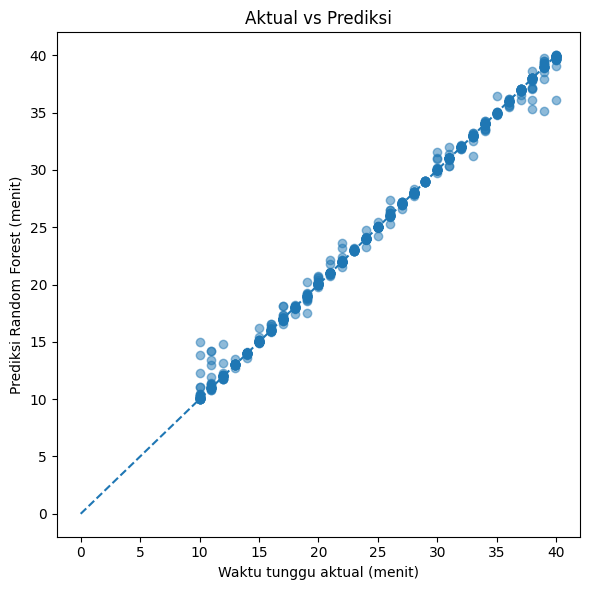

In [ ]:
hasil_prediksi = model_data.loc[X_test.index, [
    "Tanggal Kunjungan", "Nomor Antrean", "Cara Daftar", "Prioritas"
]].copy()
hasil_prediksi["Aktual (menit)"] = y_test
hasil_prediksi["Prediksi RF (menit)"] = np.maximum(0, pred_rf).round(1)
hasil_prediksi["Error Absolut (menit)"] = (
    hasil_prediksi["Aktual (menit)"] - hasil_prediksi["Prediksi RF (menit)"]
).abs().round(1)
display(hasil_prediksi.head(20))

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_rf, alpha=0.5)
max_val = max(float(y_test.max()), float(np.max(pred_rf)))
plt.plot([0, max_val], [0, max_val], linestyle="--")
plt.xlabel("Waktu tunggu aktual (menit)")
plt.ylabel("Prediksi Random Forest (menit)")
plt.title("Aktual vs Prediksi")
plt.tight_layout()
plt.show()


## **12. Feature importance**
Feature importance menunjukkan fitur mana yang paling banyak digunakan model untuk membuat prediksi. Ini bukan bukti sebab-akibat. Nama fitur setelah One-Hot Encoding bisa diekstrak dari preprocessing pipeline.

,Fitur,Importance
3,num__Jam_Pendaftaran,0.718797
5,num__Antrean_Sebelumnya,0.115020
4,num__Nomor_Antrean_Angka,0.113928
1,num__Hari_Dalam_Minggu,0.022083
2,num__Akhir_Pekan,0.018909
9,cat__Sesi_Pendaftaran_Pagi,0.005437
10,cat__Sesi_Pendaftaran_Sore,0.004669
0,num__Bulan,0.001141
7,cat__Prioritas_Tidak,0.000014
8,cat__Prioritas_Ya,0.000003


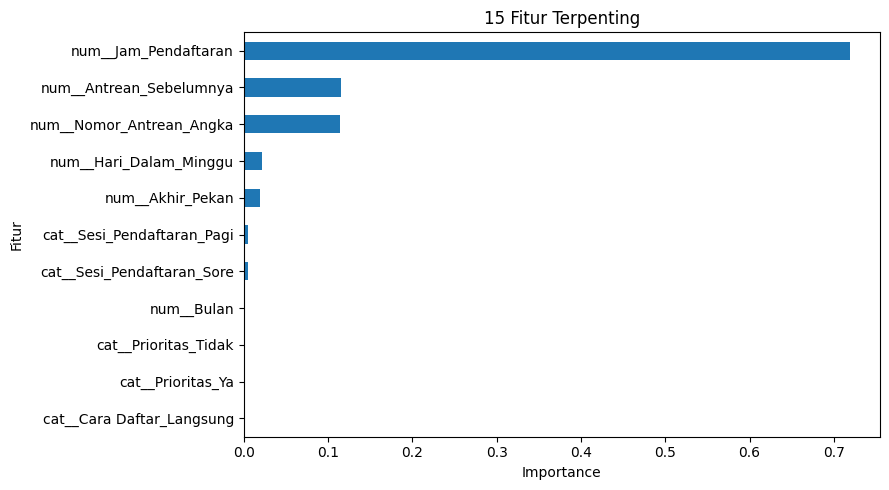

In [ ]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
importances = rf_model.named_steps["model"].feature_importances_
importance_df = pd.DataFrame({
    "Fitur": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))
importance_df.head(15).sort_values("Importance").plot(
    x="Fitur", y="Importance", kind="barh", legend=False, figsize=(9, 5)
)
plt.title("15 Fitur Terpenting")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


## **13. Fungsi estimasi untuk pasien baru**
Fungsi ini menerima data yang tersedia saat pasien mendaftar. Untuk implementasi operasional, data `Nomor Antrean`, `Cara Daftar`, `Prioritas`, tanggal dan jam pendaftaran harus berasal dari formulir/aplikasi antrean aktual.

In [ ]:
def estimasi_waktu_tunggu(
    tanggal_kunjungan,
    jam_pendaftaran,
    nomor_antrean,
    cara_daftar="Langsung",
    prioritas="Tidak"
):
    tanggal = pd.Timestamp(tanggal_kunjungan)
    jam = pd.to_datetime(jam_pendaftaran, format="%H:%M").hour + (
        pd.to_datetime(jam_pendaftaran, format="%H:%M").minute / 60
    )
    nomor = int("".join(ch for ch in str(nomor_antrean) if ch.isdigit()) or 1)
    sesi = sesi_dari_jam(jam)

    input_baru = pd.DataFrame([{
        "Bulan": tanggal.month,
        "Hari_Dalam_Minggu": tanggal.dayofweek,
        "Akhir_Pekan": int(tanggal.dayofweek == 5),
        "Jam_Pendaftaran": jam,
        "Nomor_Antrean_Angka": nomor,
        "Antrean_Sebelumnya": max(nomor - 1, 0),
        "Cara Daftar": cara_daftar,
        "Prioritas": prioritas,
        "Sesi_Pendaftaran": sesi
    }])[fitur]

    prediksi = float(rf_model.predict(input_baru)[0])
    return max(0, prediksi)

# Contoh simulasi, bukan pasien nyata:
estimasi = estimasi_waktu_tunggu(
    tanggal_kunjungan="2026-10-19",
    jam_pendaftaran="07:10",
    nomor_antrean="A005",
    cara_daftar="Langsung",
    prioritas="Tidak"
)
print(f"Estimasi waktu tunggu: {estimasi:.1f} menit")
print(f"Perkiraan mulai dilayani: sekitar {estimasi:.0f} menit setelah pendaftaran.")


Estimasi waktu tunggu: 32.7 menit
Perkiraan mulai dilayani: sekitar 33 menit setelah pendaftaran.


## **14. Simulasi monitoring antrean saat ini**
Contoh berikut menggunakan daftar antrean aktif yang dimasukkan manual. Pada aplikasi sebenarnya, ganti daftar ini dengan query database/API yang mengambil antrean saat ini dan status dokter. Model ini memperkirakan waktu tunggu dari pola historis; untuk memperbarui estimasi real-time, aplikasi harus menjalankan fungsi prediksi kembali saat antrean/status pelayanan berubah.

**Batasan penting:** fitur jumlah antrean sebelumnya di sini berasal dari nomor antrean. Ini hanya masuk akal jika nomor antrean mencerminkan urutan pelayanan. Model belum menghitung waktu layanan pasien-pasien yang masih menunggu secara eksplisit; untuk sistem yang lebih kuat, tambahkan status antrean aktif, jumlah pasien di depan, pasien yang sedang diperiksa, dan rata-rata durasi layanan historis.

In [ ]:
# Contoh antrean aktif (dummy) — ganti dengan data dari aplikasi/database
antrean_saat_ini = pd.DataFrame([
    {"Nomor Antrean": "A011", "Jam Pendaftaran": "07:35", "Cara Daftar": "Langsung", "Prioritas": "Tidak"},
    {"Nomor Antrean": "A012", "Jam Pendaftaran": "07:40", "Cara Daftar": "Online", "Prioritas": "Tidak"},
    {"Nomor Antrean": "A013", "Jam Pendaftaran": "07:45", "Cara Daftar": "Langsung", "Prioritas": "Ya"},
])

tanggal_monitoring = "2026-10-19"
antrean_saat_ini["Estimasi Tunggu (menit)"] = antrean_saat_ini.apply(
    lambda r: estimasi_waktu_tunggu(
        tanggal_kunjungan=tanggal_monitoring,
        jam_pendaftaran=r["Jam Pendaftaran"],
        nomor_antrean=r["Nomor Antrean"],
        cara_daftar=r["Cara Daftar"],
        prioritas=r["Prioritas"]
    ),
    axis=1
)
antrean_saat_ini["Estimasi Mulai Dilayani"] = antrean_saat_ini[
    "Estimasi Tunggu (menit)"
].round().astype(int).astype(str) + " menit setelah daftar"

display(antrean_saat_ini)


,Nomor Antrean,Jam Pendaftaran,Cara Daftar,Prioritas,Estimasi Tunggu (menit),Estimasi Mulai Dilayani
0,A011,07:35,Langsung,Tidak,39.854528,40 menit setelah daftar
1,A012,07:40,Online,Tidak,39.818317,40 menit setelah daftar
2,A013,07:45,Langsung,Ya,38.757048,39 menit setelah daftar


## **15. Simpan hasil cleansing, prediksi, dan model**
File Excel memuat data setelah cleansing, hasil evaluasi, dan contoh prediksi. Model disimpan agar bisa dimuat ulang oleh aplikasi Python/API.

In [18]:
OUTPUT_XLSX = "hasil_analisis_antrean.xlsx"
with pd.ExcelWriter(OUTPUT_XLSX, engine="openpyxl") as writer:
    df.drop(columns=["Detik Daftar", "Detik Mulai"], errors="ignore").to_excel(
        writer, sheet_name="Data Setelah Cleansing", index=False
    )
    hasil_evaluasi.to_excel(writer, sheet_name="Evaluasi Model", index=False)
    hasil_prediksi.to_excel(writer, sheet_name="Prediksi Testing", index=False)
    antrean_saat_ini.to_excel(writer, sheet_name="Simulasi Antrean", index=False)

import joblib
joblib.dump(rf_model, "random_forest_antrean.joblib")

print("File hasil disimpan:", OUTPUT_XLSX, "dan random_forest_antrean.joblib")

# Unduh dari Colab
from google.colab import files
files.download(OUTPUT_XLSX)
files.download("random_forest_antrean.joblib")


File hasil disimpan: hasil_analisis_antrean.xlsx dan random_forest_antrean.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **16. Kesimpulan dan batasan**
Setelah notebook dijalankan, catat nilai MAE, RMSE, dan R² dari hasil evaluasi. Jangan menyimpulkan model bagus hanya karena berhasil training.

Sebelum dipakai sungguhan:
1. Ganti data dummy dengan riwayat pelayanan nyata yang cukup dan representatif.
2. Pastikan definisi target waktu tunggu konsisten (misalnya dari pendaftaran sampai mulai diperiksa).
3. Verifikasi jadwal, tanggal merah, kunjungan dengan perjanjian, dan urutan antrean.
4. Uji pada periode tanggal yang benar-benar lebih baru daripada data training.
5. Integrasikan ke backend/database/API agar status antrean diperbarui real-time. Google Colab sendiri bukan layanan monitoring produksi yang berjalan terus-menerus.
6. Pantau error prediksi secara berkala dan latih ulang model jika pola pelayanan berubah.
